# 02 – Linear PCA baseline and biplots

**Aim.** Before trying kernels, see how far ordinary (linear) PCA gets in separating the three states
(healthy, gas injection, waxing). This is the reference that kPCA must beat, and it introduces the two
kinds of biplot used later: loading biplots and correlation biplots.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import kpca_tools as kt

FIG_DIR = "figures"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

X_raw, y = kt.load_meter_b()
X = X_raw[:, np.setdiff1d(np.arange(X_raw.shape[1]), kt.constant_columns(X_raw))]   # same as notebook 01
Z, mu, sigma = kt.zscore(X)
short = np.array(kt.SHORT_NAMES)
print("Z:", Z.shape)

Z: (92, 51)


## 1. PCA

PCA writes the autoscaled data as $Z = T P^\top$:

- $P$ ($p \times k$): **loadings**. Column $k$ is a unit-length direction in variable space; entry
  $p_{jk}$ is the weight of variable $j$ in PC $k$.
- $T = ZP$ ($n \times k$): **scores**, the coordinates of each sample along the PCs.
- $\lambda_k = \operatorname{var}(t_k)$: **eigenvalue** of the covariance matrix $Z^\top Z/(n-1)$, i.e. the
  variance captured by PC $k$. Explained-variance ratio $= \lambda_k / \sum_l \lambda_l$.

Because every variable has variance 1, the **correlation** between variable $j$ and PC $k$ is

$$r_{jk} = \frac{\operatorname{cov}(z_j, t_k)}{1 \cdot \sqrt{\lambda_k}} = \frac{p_{jk}\lambda_k}{\sqrt{\lambda_k}} = p_{jk}\sqrt{\lambda_k}.$$

So loadings and correlations point the same way; correlations additionally weight each PC by
$\sqrt{\lambda_k}$.

In [2]:
T, P, lam, evr = kt.pca(Z)
R = P * np.sqrt(lam)            # correlation of each variable with each PC (p x k)
print("T:", T.shape, " P:", P.shape)

T: (92, 51)  P: (51, 51)


## 2. Checks
These asserts confirm the relations above numerically.

In [3]:
K = 10   # check the leading PCs (the last ones have zero variance, see below)

assert np.allclose(T, Z @ P)                                   # scores = Z P
assert np.allclose(P.T @ P, np.eye(P.shape[1]))                # loadings are orthonormal
assert np.allclose(T.var(axis=0, ddof=1), lam)                 # eigenvalue = variance of the scores
assert np.isclose(evr.sum(), 1)                                # explained-variance ratios sum to 1
corr = np.array([[np.corrcoef(Z[:, j], T[:, k])[0, 1] for k in range(K)] for j in range(Z.shape[1])])
assert np.allclose(R[:, :K], corr)                             # p * sqrt(lambda) = correlation
print("All PCA checks passed.")
print(f"Eigenvalues that are numerically zero: {(lam < 1e-10).sum()}")

All PCA checks passed.
Eigenvalues that are numerically zero: 4


Four eigenvalues are zero: the four gain A/B pairs are exact duplicates (notebook 01), so the data has
rank 51 − 4 = 47.

## 3. Scree plot

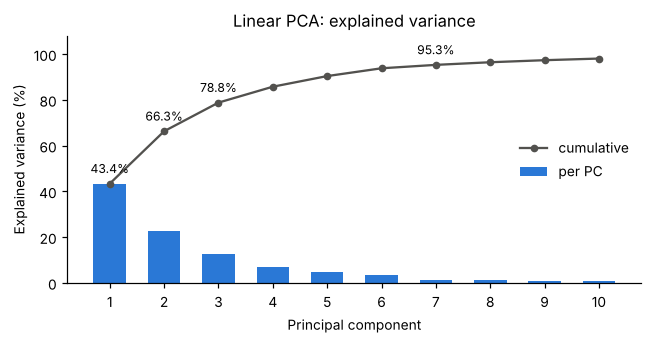

PC1:  43.4%   cumulative  43.4%
PC2:  22.9%   cumulative  66.3%
PC3:  12.5%   cumulative  78.8%
PC4:   6.9%   cumulative  85.8%
PC5:   4.6%   cumulative  90.4%
PC6:   3.4%   cumulative  93.8%
PC7:   1.5%   cumulative  95.3%


In [4]:
n_show = 10
pcs_idx = np.arange(1, n_show + 1)
cum = np.cumsum(evr)

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(pcs_idx, 100 * evr[:n_show], color=kt.CLASS_COLORS[1], width=0.6, label="per PC")
ax.plot(pcs_idx, 100 * cum[:n_show], color=kt.ARROW_COLOR, marker="o", markersize=4, lw=1.5, label="cumulative")
for k in (0, 1, 2, 6):
    ax.annotate(f"{100 * cum[k]:.1f}%", (k + 1, 100 * cum[k]), textcoords="offset points",
                xytext=(0, 7), ha="center", fontsize=8)
ax.set_xticks(pcs_idx)
ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance (%)")
ax.set_ylim(0, 108)
ax.legend(frameon=False, loc="center right")
ax.set_title("Linear PCA: explained variance")
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/m2_scree.png")
plt.show()

for k in range(7):
    print(f"PC{k + 1}: {100 * evr[k]:5.1f}%   cumulative {100 * cum[k]:5.1f}%")

## 4. Score-plot matrix, PC1–PC7
All 21 pairs of the first seven PCs, without arrows, to see quickly which planes separate the classes.

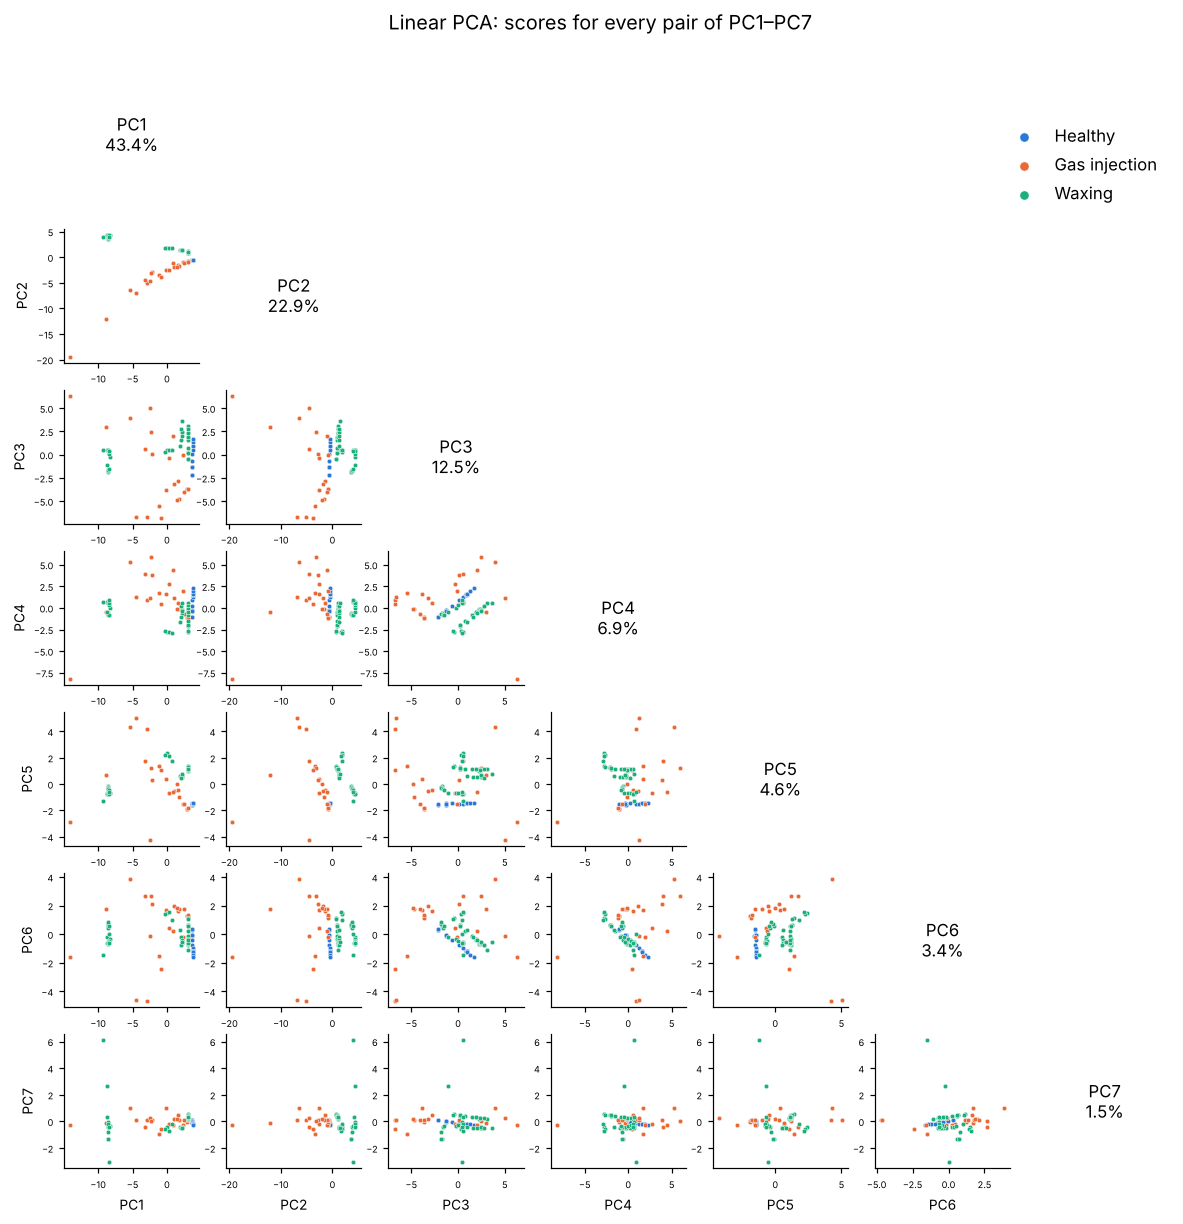

In [5]:
fig = kt.score_matrix(T, y, evr, title="Linear PCA: scores for every pair of PC1–PC7")
fig.savefig(f"{FIG_DIR}/m2_scores_matrix.png", bbox_inches="tight")
plt.show()

## 5. What drives each PC?
The five variables with the largest absolute loading on each of PC1–PC7 (sign shows the direction).

In [6]:
for k in range(7):
    top = np.argsort(-np.abs(P[:, k]))[:5]
    print(f"PC{k + 1}: " + ", ".join(f"{short[j]} ({P[j, k]:+.2f})" for j in top))

PC1: PERF (+0.21), SYM (+0.20), SS3A (+0.20), G2B (-0.20), G2A (-0.20)
PC2: SoS3 (+0.23), SoS2 (+0.23), SoSavg (+0.21), SoS1 (+0.21), TU3 (-0.21)
PC3: Vavg (+0.33), V1 (+0.32), V3 (+0.32), V2 (+0.29), V4 (+0.24)
PC4: V2 (+0.30), V3 (+0.27), Vavg (+0.26), TU2 (+0.24), V1 (+0.23)
PC5: SWA (+0.42), TU4 (+0.28), SS4A (-0.25), TT1B (-0.25), TT1A (-0.25)
PC6: TU1 (+0.44), TT1B (+0.31), TT1A (+0.31), SoS1 (+0.30), TU4 (+0.25)
PC7: PF (+0.93), SWA (+0.18), SoSavg (-0.15), G3A (-0.12), G3B (-0.12)


## 6. Loading biplots
Six consecutive planes (PC1–PC2, …, PC6–PC7) cover all of the first seven PCs. Arrows are the loadings
$p_{jk}$ of the 15 variables with the longest arrow in that plane. Loadings and scores have different
units, so the arrows are multiplied by one factor per panel to fit the score cloud: only **directions**
and **relative lengths within a panel** are meaningful.

How to read it: a sample lies far along an arrow when it has high values of that variable; arrows
pointing the same way are positively correlated, opposite arrows negatively correlated.

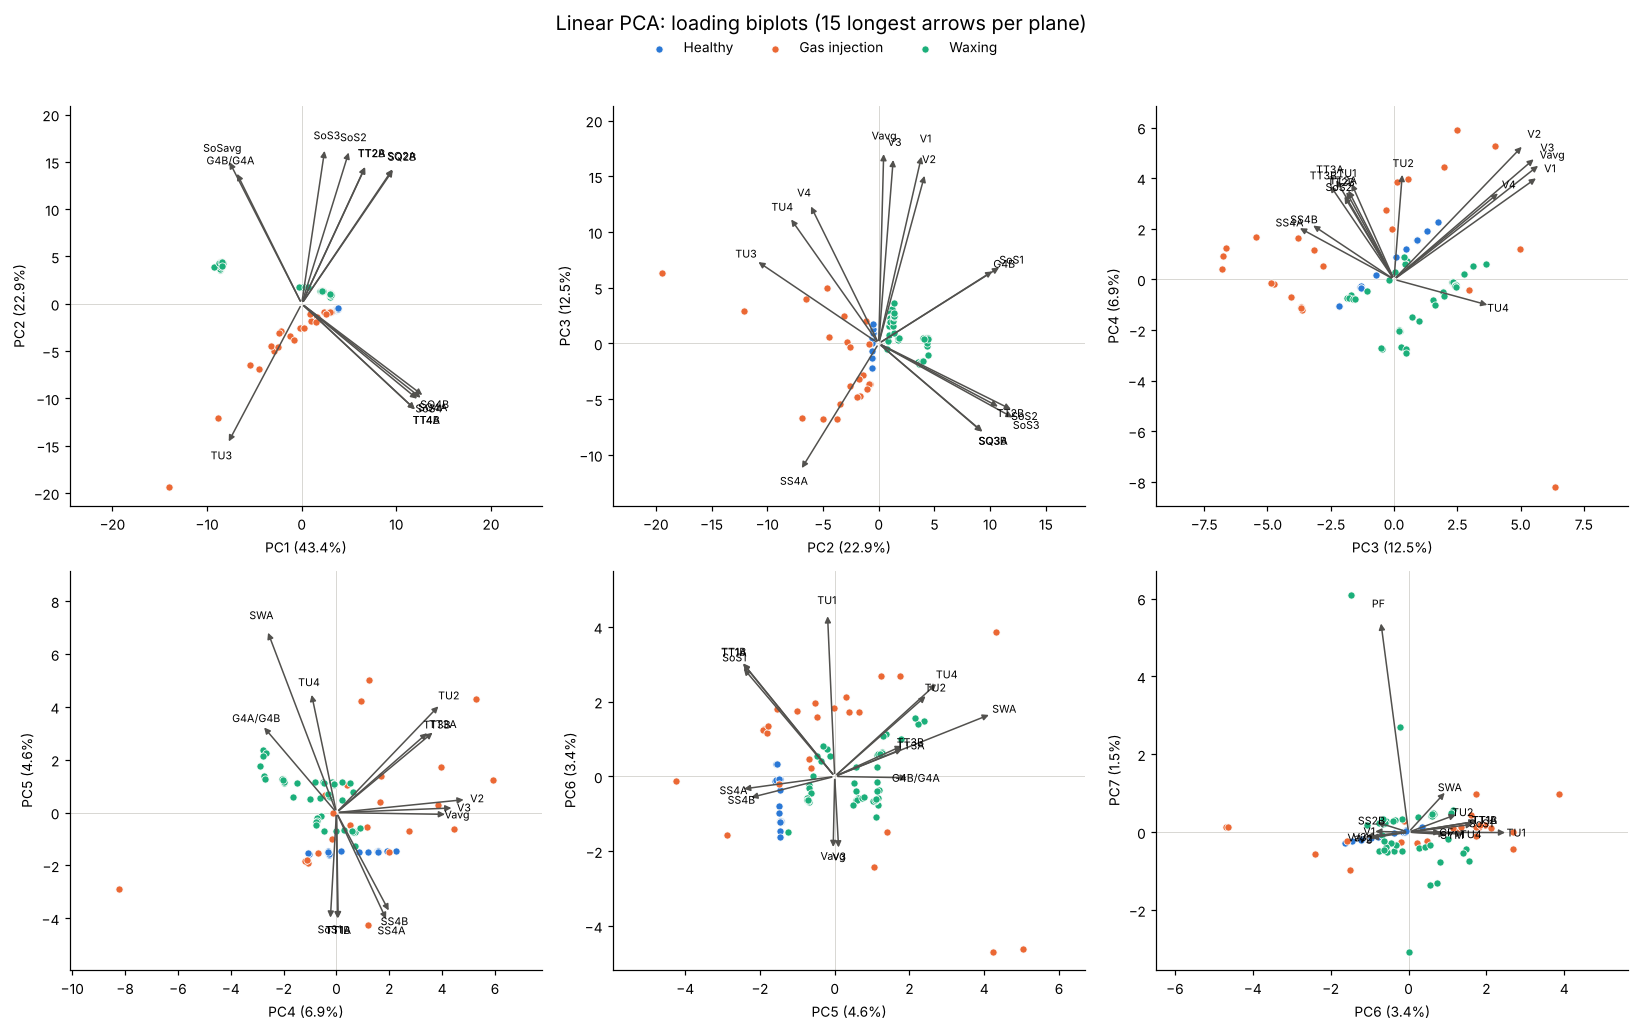

In [7]:
fig = kt.biplot_grid(T, P, y, short, evr, circle=False,
                     title="Linear PCA: loading biplots (15 longest arrows per plane)")
fig.savefig(f"{FIG_DIR}/m2_biplots_loadings.png")
plt.show()

## 7. Correlation biplots
Same planes, but the arrows are correlations $r_{jk} = p_{jk}\sqrt{\lambda_k}$. The dashed circle marks
correlation = 1: an arrow reaching the circle means the variable is almost fully described by these two
PCs. Compared with the loading biplots, the arrows are stretched along the PC with the larger
eigenvalue, so they show how much of each variable a plane actually explains.

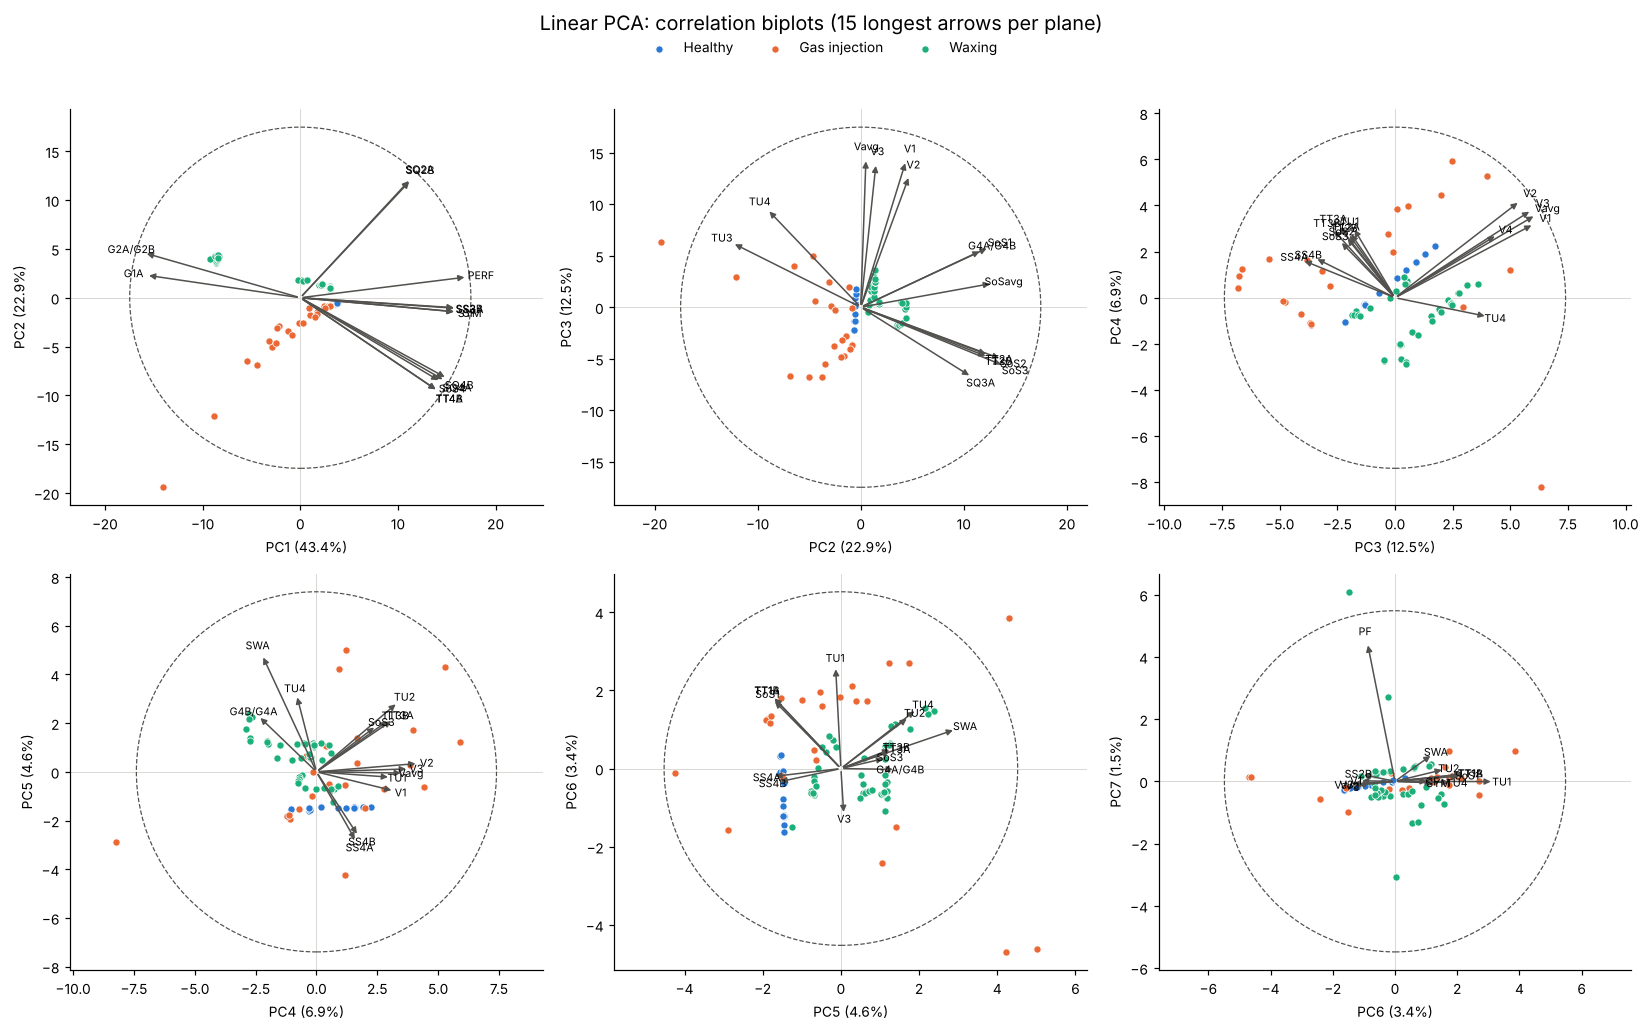

In [8]:
fig = kt.biplot_grid(T, R, y, short, evr, circle=True,
                     title="Linear PCA: correlation biplots (15 longest arrows per plane)")
fig.savefig(f"{FIG_DIR}/m2_biplots_correlations.png")
plt.show()

## 8. Class ranges along each PC
Minimum and maximum score of each class on PC1–PC7, plus the spread (std) within each class. If the ranges
of two classes do not overlap on a PC, that single PC already separates them.

In [9]:
print(f"{'':5}" + "".join(f"{kt.CLASS_NAMES[c]:>26}" for c in kt.CLASS_NAMES))
for k in range(7):
    row = f"PC{k + 1:<3} "
    for c in kt.CLASS_NAMES:
        t = T[y == c, k]
        row += f"   [{t.min():6.1f}, {t.max():5.1f}] sd {t.std(ddof=1):3.1f}"
    print(row)

drop = np.arange(77, 92)   # path-4 dropout samples (notebook 01)
print(f"\nPath-4 dropout samples: PC1 in [{T[drop, 0].min():.1f}, {T[drop, 0].max():.1f}], "
      f"PC2 in [{T[drop, 1].min():.1f}, {T[drop, 1].max():.1f}]")
k = np.argmax(np.abs(T[:, 6]))
print(f"Largest |PC7| score: sample {k + 1} ({kt.CLASS_NAMES[y[k]]}), profile factor = {X[k, 0]:.2f} "
      f"(median of all samples {np.median(X[:, 0]):.2f})")

                        Healthy             Gas injection                    Waxing
PC1      [   3.6,   3.8] sd 0.1   [ -14.1,   3.0] sd 4.1   [  -9.2,   3.1] sd 5.2
PC2      [  -0.6,  -0.5] sd 0.0   [ -19.4,  -0.8] sd 4.2   [   0.7,   4.4] sd 1.4
PC3      [  -2.2,   1.7] sd 1.3   [  -6.8,   6.3] sd 3.9   [  -1.9,   3.6] sd 1.4
PC4      [  -1.1,   2.3] sd 1.1   [  -8.2,   5.9] sd 2.9   [  -2.9,   0.9] sd 1.1
PC5      [  -1.6,  -1.4] sd 0.0   [  -4.3,   5.0] sd 2.3   [  -1.3,   2.4] sd 0.9
PC6      [  -1.6,   0.3] sd 0.6   [  -4.7,   3.9] sd 2.2   [  -1.5,   1.6] sd 0.7
PC7      [  -0.3,   0.1] sd 0.1   [  -1.0,   1.0] sd 0.4   [  -3.1,   6.1] sd 1.2

Path-4 dropout samples: PC1 in [-9.2, -8.3], PC2 in [3.6, 4.4]
Largest |PC7| score: sample 87 (Waxing), profile factor = 10.21 (median of all samples 1.27)


## 9. Interpretation

**Variance.** PC1–PC3 explain 78.8 % of the variance and PC1–PC7 explain 95.3 %; after PC7 each PC adds
less than 1.1 %.

**What each PC represents** (sections 5–7):
- **PC1 (43.4 %)** – overall signal health: meter performance, signal strength and symmetry on one side,
  gain on the other. Low PC1 means weak signals and high gain.
- **PC2 (22.9 %)** – speed of sound (paths 1–3 and the average) against turbulence on path 3.
- **PC3 and PC4 (12.5 %, 6.9 %)** – flow velocities. These describe the *operating point* (how fast the
  liquid flows), not a fault: the healthy samples, which are otherwise almost identical, spread only along
  PC3 and PC4.
- **PC5 and PC6** – swirl angle and turbulence on paths 1 and 4, path-4 signal strength, path-1 transit time.
- **PC7 (1.5 %)** – almost only the profile factor (loading 0.93), driven by one waxing sample with an
  extreme profile factor.

**Separation of the classes.**
- **PC2 alone separates the three classes**: their PC2 ranges do not overlap (section 8). Waxing lies
  above, gas injection below, and the healthy samples in a very narrow band between them. The gap between
  healthy and the nearest gas-injection sample is small (about 0.3), so this separation is not robust.
- **Healthy** samples form a very tight group (std ≈ 0 on PC1, PC2 and PC5). This follows from notebook
  01: 17 variables take a single value in the healthy state.
- **Gas injection** samples spread along a long line in the PC1–PC2 plane, from the healthy group towards
  very low PC1 and PC2 (weaker signals, higher turbulence). This looks like increasing fault severity: the
  mildest gas-injection samples lie closest to the healthy group.
- **Waxing** samples split into two groups: the 15 path-4 dropout samples form a separate cluster
  (PC1 ≈ −9, PC2 ≈ 4), and the other waxing samples lie close to the healthy group on PC1 but above it on
  PC2. Waxing also lies above healthy along PC5: only just for the dropout samples, clearly for the
  others (lowest score 0.5, against at most −1.4 for healthy).
- **Loading vs. correlation biplots** tell the same story. The correlation biplots make clear that the
  variables in the PC1–PC2 plane are well explained there (arrows near the circle), while in the PC6–PC7
  plane all arrows are short, i.e. those PCs explain little of any variable except the profile factor.

## Summary – carried into Milestone 3
- Linear PCA already separates the three states, mainly along PC2, but the healthy and gas-injection
  groups nearly touch, and waxing is split into two clusters by the path-4 dropout.
- The structure is partly **non-linear**: gas injection moves away from the healthy group along a path that is
  straight in PC1–PC2 but bends in PC1–PC3 and PC2–PC3,
  and waxing consists of two separate groups. kPCA may be able to pull the classes further apart and give
  each class a more compact shape.
- So the question for kPCA is not only *whether* it separates the classes, but whether it does so with a
  **larger margin**, in fewer components, and with more compact classes than linear PCA. This sets the
  baseline for Milestones 3–5.
